In [1]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
import camb
import statistics
import hankl

In [2]:
data_on = '/data/desi/scratch/lfloresl/ASTRID/ASTRID/data/spectra_ASTRID_z2.5_500x500x2500.hdf5'  # With self-shielding

with h5py.File(data_on, 'r') as f:
    print('Keys:', f.keys())
    header_on = f['Header']
    print('------ Header ------')
    for attr in header_on.attrs:
            print(f"{attr} : {header_on.attrs[attr]}")
    print('------ Data ------')
    colden = f['colden/H/1'][:]
    print('colden shape:', colden.shape)  

Keys: <KeysViewHDF5 ['Header', 'colden', 'spectra', 'tau']>
------ Header ------
Hz : 252.87249366801257
box : 250000.0
discarded : 0
hubble : 0.6774
nbins : 2500
npart : [165988309584 166375000000            0            0  10297622146
     11325619]
omegab : 0.0486
omegal : 0.6911
omegam : 0.3089
redshift : 2.499999947500001
------ Data ------
colden shape: (250000, 2500)


In [3]:
print('----- Useful information -----')
Lbox = 250  # Mpc/h
print('box size:', Lbox, 'Mpc/h')

# Number of skewers per side
Nsk = int(np.sqrt(colden.shape[0]))  # colden.on_shape[0] gives the size of the axis
print(Nsk,'skewers per side')

# Number of pixels per skewer
Np = colden.shape[1] # colden.on_shape[1] gives the size of the columns
print(Np, 'pixels per skewer')

# Pixel width 
Pw = Lbox/Np  # Mpc/h 
print(Pw, 'Mpc/h pixel width')
# We are dividing the total box width in comoving units by the number of pixels in each skewer

# Minimum separation between skewers
Ssk = Lbox/Nsk  # Mpc/h 
print(Ssk, 'Mpc/h skewer separation')
# We are dividing the total box width in comoving units by the number of skewers per side

----- Useful information -----
box size: 250 Mpc/h
500 skewers per side
2500 pixels per skewer
0.1 Mpc/h pixel width
0.5 Mpc/h skewer separation


# Dark matter

As we will need both the power spectra and the 2pcf for dm, let's calculate them first

## Isotropic power spectrum

In [4]:
hubble, z = 0.6774, 2.5
omegab, omegam = 0.0486, 0.3089  # Using ASTRID simulation parameters
ns, As = 0.9667, 2.142e-9
pars = camb.set_params(H0=100*hubble, ombh2=omegab*(hubble**2), omch2=omegam*(hubble**2), ns=ns, As=As)

In [5]:
pars.set_matter_power(redshifts=[z], kmax=100)
pars.NonLinear = camb.model.NonLinear_none  # Linear spectra
results = camb.get_results(pars)
k_dm, _, pk = results.get_linear_matter_power_spectrum(hubble_units=True, k_hunit=True) 
p_dm = pk[0, :]

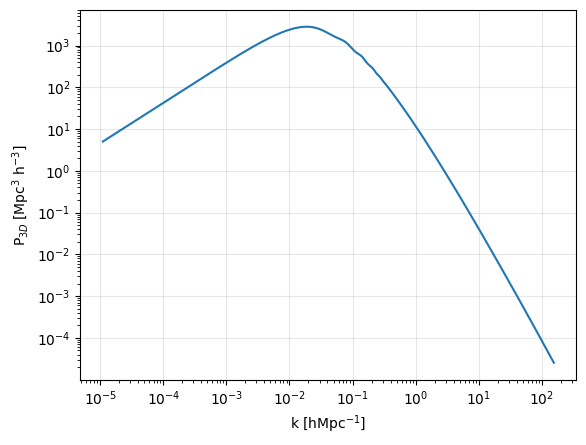

In [6]:
plt.plot(k_dm, p_dm)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'k [hMpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$ h$^{-3}$]')
plt.grid(alpha=0.3);

# ASTRID data

In [7]:
colden[colden<=0] = np.nan  # To avoid problems with logarithms
colden_log = np.log10(colden)
print(colden_log.shape)
del colden

(250000, 2500)


In [8]:
def coord_Mpc_h(colden, colden_min, colden_max, h=0.7, h_units=True):
    """ This functions gives back the coordinates (in Mpc/h if h_units=True) of those systems with a value
    of column density such as colden_min < colden < colden_max

    Parameters:
    ----------------
    colden : narray
        (Log10) Column density values of the simulation box
    colden_min : value
        Lowest limit on (log10) column density values to be considered
    colden_max : value
        Highest limit on (log10) column density values to be considered
    h : value
        Little Hubble constant value
    h_units : Boolean
        Wether we want the returned coordinates to be in units of h or not. By default, True.

    Returns:
    ---------------
    x, y, z : arrays
        Coordinate values in Mpc/h of pixels with column density within the defined range

    """

    Lbox = 250  # Mpc/h
    Nsk, Np = 500, 2500  # Number of skewers in box and number of pixels in each skewer
    Pw = Lbox/Np  # Pixel width in Mpc/h
    Skw = Lbox/Nsk  # Skewer "width" in Mpc/h 
    
    mask = (colden > colden_min) & (colden < colden_max) 
    skewer_idx, z_idx = np.where(mask)
    x_idx = skewer_idx % Nsk  # % Returns remainder of division 
    y_idx = skewer_idx // Nsk  # // Returns floor of division result (largest integer that is less than or equal to the result of the division)

    x = (x_idx + Ssk/2) * Ssk
    y = (y_idx + Ssk/2) * Ssk
    z = (z_idx + Pw/2) * Pw

    if h_units == False:
        x /= h
        y /= h
        z /= h

    return x, y, z

## Power spectrum

### Different HCDs

In [9]:
x_hcd, y_hcd, z_hcd = coord_Mpc_h(colden_log, 19, 22, h=hubble, h_units=True)  # Same Nhi range as in MW11
x_lls, y_lls, z_lls = coord_Mpc_h(colden_log, 17.22, 20, h=hubble, h_units=True)  # Mpc/h
x_subdla, y_subdla, z_subdla = coord_Mpc_h(colden_log, 20, 20.3, h=hubble, h_units=True)  # Mpc/h
x_smalldla, y_smalldla, z_smalldla = coord_Mpc_h(colden_log, 20.3, 21, h=hubble, h_units=True)  # Mpc/h
x_largedla, y_largedla, z_largedla = coord_Mpc_h(colden_log, 21, 22, h=hubble, h_units=True)  # Mpc/h

In [10]:
from nbodykit.lab import *

Boxsize = Lbox  # Mpc/h
dk = 2*np.pi/Boxsize  # Step of k
Nmesh = 244*2  # Increasing this number increases k_max I can trust 

In [11]:
# HCDs
# We first create a catalog with the positions:
cat = ArrayCatalog({'Position': np.c_[x_hcd, y_hcd, z_hcd]})
# From it we create a mesh
mesh = cat.to_mesh(BoxSize=Boxsize, Nmesh=Nmesh, compensated=True, resampler='cic', position='Position')
# Calculate fourier transform
r = FFTPower(mesh, mode='1d', dk=dk)
k_hcd, p3d_hcd = r.power['k'][1:], r.power['power'][1:].real-r.power.attrs['shotnoise']  # First value is a bit skechy

p_dm_interp = np.interp(k_hcd, k_dm, p_dm)
ratio_hcd = p3d_hcd/p_dm_interp

In [12]:
# LLS
cat = ArrayCatalog({'Position': np.c_[x_lls, y_lls, z_lls]})
mesh = cat.to_mesh(BoxSize=Boxsize, Nmesh=Nmesh, compensated=True, resampler='cic', position='Position')
r = FFTPower(mesh, mode='1d', dk=dk)
k_lls, p3d_lls = r.power['k'][1:], r.power['power'][1:].real-r.power.attrs['shotnoise']  # First value is a bit skechy

p_dm_interp = np.interp(k_lls, k_dm, p_dm)
ratio_lls = p3d_lls/p_dm_interp

In [13]:
# subDLAs
cat = ArrayCatalog({'Position': np.c_[x_subdla, y_subdla, z_subdla]})
mesh = cat.to_mesh(BoxSize=Boxsize, Nmesh=Nmesh, compensated=True, resampler='cic', position='Position')
r = FFTPower(mesh, mode='1d', dk=dk)
k_subdla, p3d_subdla = r.power['k'][1:], r.power['power'][1:].real-r.power.attrs['shotnoise']  # First value is skechy

p_dm_interp = np.interp(k_subdla, k_dm, p_dm)
ratio_subdla = p3d_subdla/p_dm_interp

In [14]:
# small DLAs
cat = ArrayCatalog({'Position': np.c_[x_smalldla, y_smalldla, z_smalldla]})
mesh = cat.to_mesh(BoxSize=Boxsize, Nmesh=Nmesh, compensated=True, resampler='cic', position='Position')
r = FFTPower(mesh, mode='1d', dk=dk)
k_smalldla, p3d_smalldla = r.power['k'][1:], r.power['power'][1:].real-r.power.attrs['shotnoise']  # First value is a bit skechy

p_dm_interp = np.interp(k_smalldla, k_dm, p_dm)
ratio_smalldla = p3d_smalldla/p_dm_interp

In [15]:
# Large DLAs
cat = ArrayCatalog({'Position': np.c_[x_largedla, y_largedla, z_largedla]})
mesh = cat.to_mesh(BoxSize=Boxsize, Nmesh=Nmesh, compensated=True, resampler='cic', position='Position')
r = FFTPower(mesh, mode='1d', dk=dk)
k_largedla, p3d_largedla = r.power['k'][1:], r.power['power'][1:].real-r.power.attrs['shotnoise']  # First value is a bit skechy

p_dm_interp = np.interp(k_largedla, k_dm, p_dm)
ratio_largedla = p3d_largedla/p_dm_interp

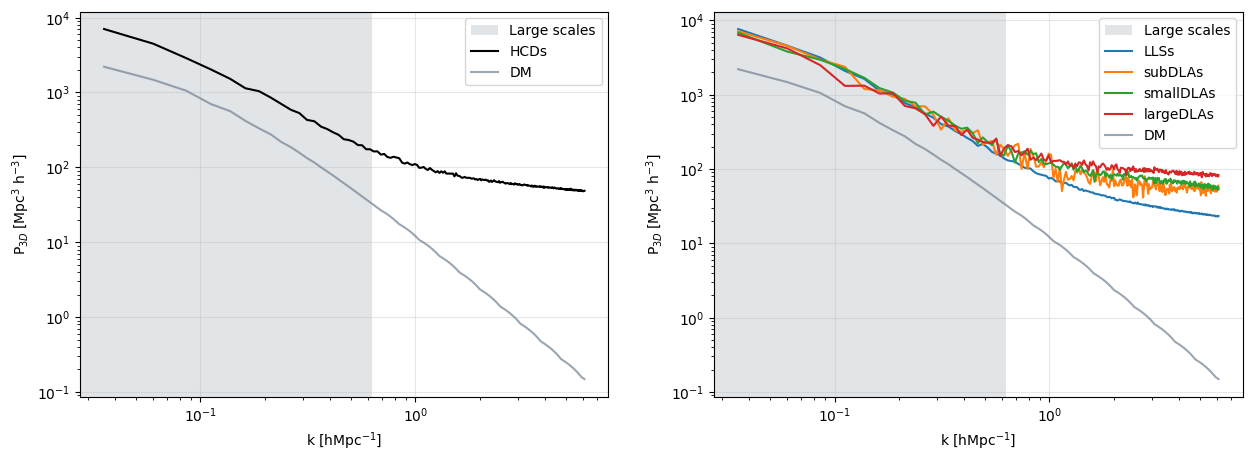

In [16]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.axvspan(0, 2*np.pi/10, facecolor='slategrey', alpha=0.2, label='Large scales')
plt.plot(k_hcd, p3d_hcd, color='k', label='HCDs')
plt.plot(k_hcd, p_dm_interp, color='slategrey', alpha=0.7, label='DM')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [hMpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$ h$^{-3}$]')
plt.legend();

plt.subplot(1, 2, 2)
plt.axvspan(0, 2*np.pi/10, facecolor='slategrey', alpha=0.2, label='Large scales')
plt.plot(k_lls, p3d_lls, label='LLSs')
plt.plot(k_subdla, p3d_subdla, label='subDLAs')
plt.plot(k_smalldla, p3d_smalldla, label='smallDLAs')
plt.plot(k_largedla, p3d_largedla, label='largeDLAs')
plt.plot(k_hcd, p_dm_interp, color='slategrey', alpha=0.7, label='DM')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [hMpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{3}$ h$^{-3}$]')
plt.legend();

In [20]:
bias_hcd = np.sqrt(ratio_hcd)
bias_lls = np.sqrt(ratio_lls)
bias_subdla = np.sqrt(ratio_subdla)
bias_smalldla = np.sqrt(ratio_smalldla)
bias_largedla = np.sqrt(ratio_largedla)

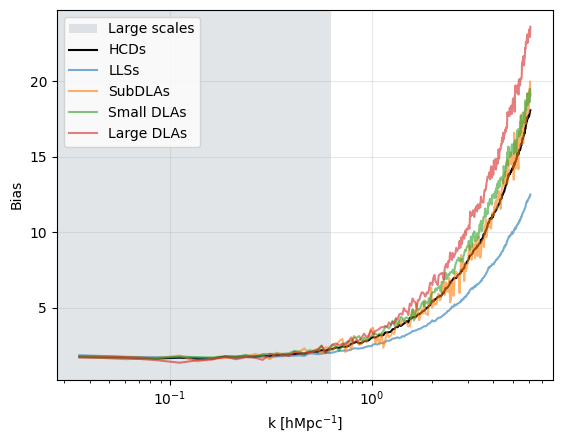

In [21]:
plt.axvspan(0, 2*np.pi/10, facecolor='slategrey', alpha=0.2, label='Large scales')
plt.plot(k_hcd, bias_hcd, color='k', label='HCDs')
plt.plot(k_lls, bias_lls, alpha=0.6, label='LLSs')
plt.plot(k_subdla, bias_subdla, alpha=0.6, label='SubDLAs')
plt.plot(k_smalldla, bias_smalldla, alpha=0.6, label='Small DLAs')
plt.plot(k_largedla, bias_largedla, alpha=0.6, label='Large DLAs')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [hMpc$^{-1}$]')
plt.ylabel(r'Bias')
plt.legend();

As this is a large-scale bias, we only want to keep values for r > 10 Mpc => k < 2pi/10 h/Mpc 

In [22]:
mask_hcd = (k_hcd < (2*np.pi/10)) 
mask_lls = (k_lls < (2*np.pi/10)) 
mask_subdla = (k_subdla < (2*np.pi/10)) 
mask_smalldla = (k_smalldla < (2*np.pi/10)) 
mask_largedla = (k_largedla < (2*np.pi/10)) 

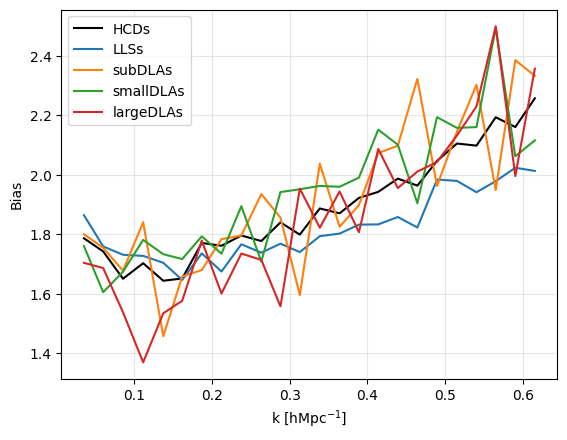

In [23]:
plt.plot(k_hcd[mask_hcd], np.sqrt(ratio_hcd[mask_hcd]), color='k', label='HCDs')
plt.plot(k_lls[mask_lls], np.sqrt(ratio_lls[mask_lls]), label='LLSs')
plt.plot(k_subdla[mask_subdla], np.sqrt(ratio_subdla[mask_subdla]), label='subDLAs')
plt.plot(k_smalldla[mask_smalldla], np.sqrt(ratio_smalldla[mask_smalldla]), label='smallDLAs')
plt.plot(k_largedla[mask_largedla], np.sqrt(ratio_largedla[mask_largedla]), label='largeDLAs')
plt.grid(alpha=0.3)
plt.xlabel(r'k [hMpc$^{-1}$]')
plt.ylabel(r'Bias')
plt.legend();

In [24]:
bias_hcd, bias_hcd_std = np.nanmean(bias_hcd[mask_hcd]), np.nanstd(bias_hcd[mask_hcd])
bias_lls, bias_lls_std = np.nanmean(bias_lls[mask_lls]), np.nanstd(bias_lls[mask_lls])
bias_subdla, bias_subdla_std = np.nanmean(bias_subdla[mask_subdla]), np.nanstd(bias_subdla[mask_subdla])
bias_smalldla, bias_smalldla_std = np.nanmean(bias_smalldla[mask_smalldla]), np.nanstd(bias_smalldla[mask_smalldla])
bias_largedla, bias_largedla_std = np.nanmean(bias_largedla[mask_largedla]), np.nanstd(bias_largedla[mask_largedla])
print('HCDs bias=', bias_hcd, '+-', bias_hcd_std)
print('LLSs bias=', bias_lls, '+-', bias_lls_std)
print('Sub-dlas bias=', bias_subdla, '+-', bias_subdla_std)
print('Small DLAs bias=', bias_smalldla, '+-', bias_smalldla_std)
print('Large DLAs bias=', bias_largedla, '+-', bias_largedla_std)

HCDs bias= 1.8894217236171602 +- 0.17535022313598242
LLSs bias= 1.8212533296056206 +- 0.1091369996961149
Sub-dlas bias= 1.9231481094210519 +- 0.24282151973517682
Small DLAs bias= 1.9390759207936608 +- 0.2081407049275998
Large DLAs bias= 1.859285377070713 +- 0.27439964125444105


## Comparison with correlation function -obtained bias

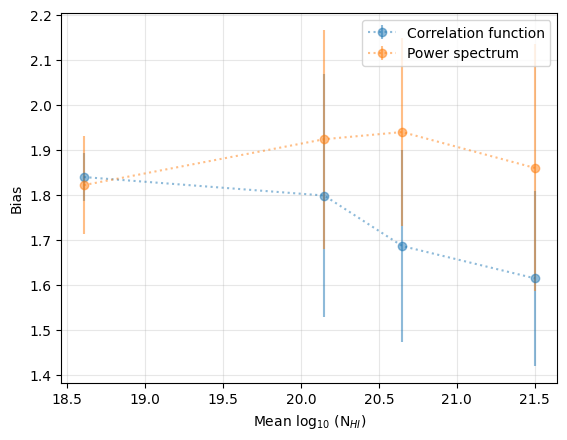

In [25]:
mean_colden = [18.61, 20.15, 20.65, 21.5]
y_power = [bias_lls, bias_subdla, bias_smalldla, bias_largedla]
yerr_power = [bias_lls_std, bias_subdla_std, bias_smalldla_std, bias_largedla_std]
y_corrfunc = [1.7809352586489902, 1.7413124133048492, 1.6324346929214324, 1.5630714681240068]
yerr_corrfunc = [0.05327948725500541, 0.2626979069535987, 0.20574732050955405, 0.1894668756689997]
plt.errorbar(mean_colden, y=y_corrfunc, yerr=yerr_corrfunc, linestyle='dotted', marker='o', alpha=0.5, label='Correlation function')
plt.errorbar(mean_colden, y=y_power, yerr=yerr_power, linestyle='dotted', marker='o', alpha=0.5, label='Power spectrum')
plt.xlabel(r'Mean log$_{10}$ (N$_{HI}$)')
plt.ylabel('Bias')
plt.grid(alpha=0.3)
plt.legend();

## Different scale cuts

Jonás suggested it would improve the measurements if the scale cuts were different for each logNHi range we are considering. Higher NHi would need higher scales to be considered large enough. We will use the corresponding k values to the r cuts imposed in the correlation function. That is:

In [29]:
bias_lls = np.sqrt(ratio_lls)
bias_subdla = np.sqrt(ratio_subdla)
bias_smalldla = np.sqrt(ratio_smalldla)
bias_largedla = np.sqrt(ratio_largedla)

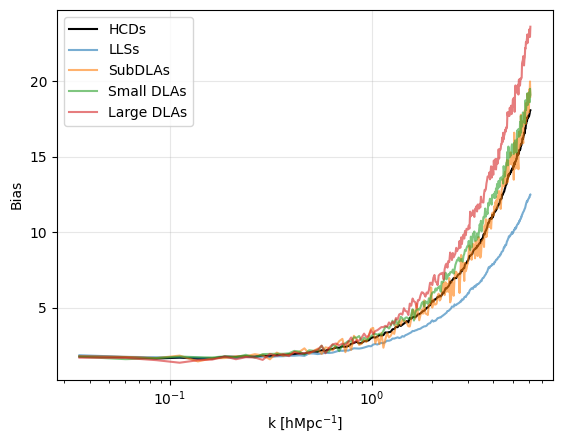

In [19]:
plt.plot(k_hcd, bias_hcd, color='k', label='HCDs')
plt.plot(k_lls, bias_lls, alpha=0.6, label='LLSs')
plt.plot(k_subdla, bias_subdla, alpha=0.6, label='SubDLAs')
plt.plot(k_smalldla, bias_smalldla, alpha=0.6, label='Small DLAs')
plt.plot(k_largedla, bias_largedla, alpha=0.6, label='Large DLAs')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [hMpc$^{-1}$]')
plt.ylabel(r'Bias')
plt.legend();

In [30]:
mask_lls = (k_lls < (2*np.pi/10)) 
mask_subdla = (k_subdla < (2*np.pi/13)) 
mask_smalldla = (k_smalldla < (2*np.pi/15)) 
mask_largedla = (k_largedla < (2*np.pi/17)) 

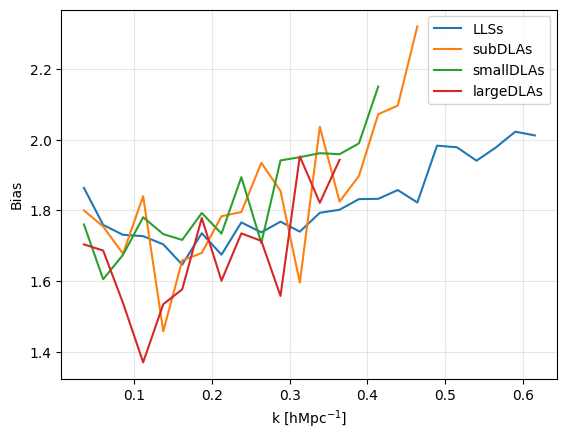

In [22]:
plt.plot(k_lls[mask_lls], np.sqrt(ratio_lls[mask_lls]), label='LLSs')
plt.plot(k_subdla[mask_subdla], np.sqrt(ratio_subdla[mask_subdla]), label='subDLAs')
plt.plot(k_smalldla[mask_smalldla], np.sqrt(ratio_smalldla[mask_smalldla]), label='smallDLAs')
plt.plot(k_largedla[mask_largedla], np.sqrt(ratio_largedla[mask_largedla]), label='largeDLAs')
plt.grid(alpha=0.3)
plt.xlabel(r'k [hMpc$^{-1}$]')
plt.ylabel(r'Bias')
plt.legend();

In [31]:
bias_lls_m, bias_lls_std_m = np.nanmean(bias_lls[mask_lls]), np.nanstd(bias_lls[mask_lls])
bias_subdla_m, bias_subdla_std_m = np.nanmean(bias_subdla[mask_subdla]), np.nanstd(bias_subdla[mask_subdla])
bias_smalldla_m, bias_smalldla_std_m = np.nanmean(bias_smalldla[mask_smalldla]), np.nanstd(bias_smalldla[mask_smalldla])
bias_largedla_m, bias_largedla_std_m = np.nanmean(bias_largedla[mask_largedla]), np.nanstd(bias_largedla[mask_largedla])
print('LLSs bias=', bias_lls_m, '+-', bias_lls_std_m)
print('Sub-dlas bias=', bias_subdla_m, '+-', bias_subdla_std_m)
print('Small DLAs bias=', bias_smalldla_m, '+-', bias_smalldla_std_m)
print('Large DLAs bias=', bias_largedla_m, '+-', bias_largedla_std_m)

LLSs bias= 1.8212533296056206 +- 0.1091369996961149
Sub-dlas bias= 1.8379136920992307 +- 0.19856109180485387
Small DLAs bias= 1.8345660803258923 +- 0.14229267762243306
Large DLAs bias= 1.6793356362485954 +- 0.15777449085692508


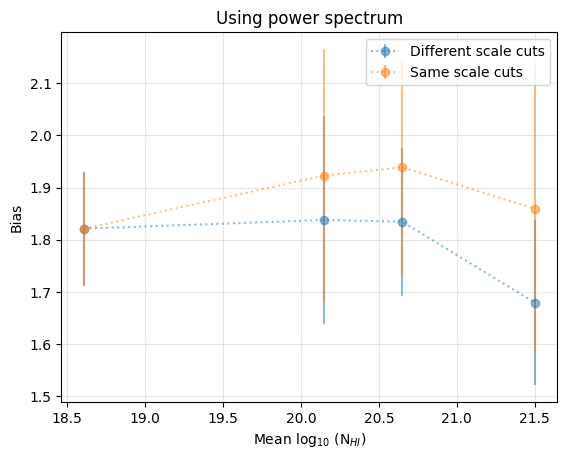

In [35]:
mean_colden = [18.61, 20.15, 20.65, 21.5]
y_power = [bias_lls_m, bias_subdla_m, bias_smalldla_m, bias_largedla_m]
yerr_power = [bias_lls_std_m, bias_subdla_std_m, bias_smalldla_std_m, bias_largedla_std_m]
y_power2 = [1.8212533296056206, 1.9231481094210519, 1.9390759207936608, 1.859285377070713]
yerr_power2 = [0.1091369996961149, 0.24282151973517682, 0.2081407049275998, 0.27439964125444105]
plt.errorbar(mean_colden, y=y_power, yerr=yerr_power, linestyle='dotted', marker='o', alpha=0.5, label='Different scale cuts')
plt.errorbar(mean_colden, y=y_power2, yerr=yerr_power2, linestyle='dotted', marker='o', alpha=0.5, label='Same scale cuts')
plt.xlabel(r'Mean log$_{10}$ (N$_{HI}$)')
plt.ylabel('Bias')
plt.grid(alpha=0.3)
plt.legend()
plt.title('Using power spectrum');

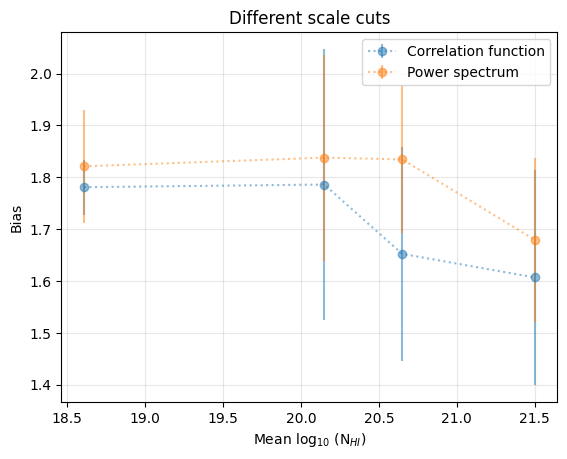

In [36]:
mean_colden = [18.61, 20.15, 20.65, 21.5]
y_power = [bias_lls_m, bias_subdla_m, bias_smalldla_m, bias_largedla_m]
yerr_power = [bias_lls_std_m, bias_subdla_std_m, bias_smalldla_std_m, bias_largedla_std_m]
y_corrfunc = [1.7809352586489902, 1.7860280891023377, 1.652364616722669, 1.606842440691771]
yerr_corrfunc = [0.05327948725500541, 0.26154069104980904, 0.20703555415489222, 0.20719168073211233]
plt.errorbar(mean_colden, y=y_corrfunc, yerr=yerr_corrfunc, linestyle='dotted', marker='o', alpha=0.5, label='Correlation function')
plt.errorbar(mean_colden, y=y_power, yerr=yerr_power, linestyle='dotted', marker='o', alpha=0.5, label='Power spectrum')
plt.xlabel(r'Mean log$_{10}$ (N$_{HI}$)')
plt.ylabel('Bias')
plt.grid(alpha=0.3)
plt.legend()
plt.title('Different scale cuts');